# **RoBERTa-base with Class-Weighted Focal Loss, Metadata Augmentation and Threshold Skimming**

## 0. Setup

In [43]:
import os, re, json, random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import IPython

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import precision_recall_fscore_support, multilabel_confusion_matrix, precision_recall_curve, average_precision_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
 )

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

DEVICE: cuda


In [ ]:
def set_seed(seed: int = 42):
    """Set seeds for reproducibility across Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

def ensure_dir(p: Path):
    """Create a directory (and parents) if it does not exist."""
    p.mkdir(parents=True, exist_ok=True)

In [5]:
DATA_PATH = 'dontpatronizeme_pcl.tsv'
TRAIN_PATH = 'train_semeval_parids-labels.csv'
DEV_PATH = 'dev_semeval_parids-labels.csv'
TEST_PATH = 'task4_test.tsv'

OUT_DIR = Path('/vol/bitbucket/ak5323/nlp_cw_2026_ak5323/output')

TEXT_COL = 'paragraph_text'
LABEL_COL = 'binary_label'

## 1. Load data (train/dev/test)

In [6]:
col_names = ['paragraph_id', 'article_id', 'keyword', 'country_code', 'paragraph_text', 'pcl_category']
df_all = pd.read_csv(DATA_PATH, sep='\t', header=None, names=col_names, skiprows=4)

In [7]:
train_ids_df = pd.read_csv(TRAIN_PATH)
dev_ids_df = pd.read_csv(DEV_PATH)

In [8]:
df_all['paragraph_id'] = pd.to_numeric(df_all['paragraph_id'], errors='coerce')
df_all = df_all.dropna(subset=['paragraph_id'])
df_all['paragraph_id'] = df_all['paragraph_id'].astype(int)

In [9]:
train_ids_df['par_id'] = pd.to_numeric(train_ids_df['par_id'], errors='coerce')
train_ids_df = train_ids_df.dropna(subset=['par_id'])
train_ids_df['par_id'] = train_ids_df['par_id'].astype(int)

In [10]:
dev_ids_df['par_id'] = pd.to_numeric(dev_ids_df['par_id'], errors='coerce')
dev_ids_df = dev_ids_df.dropna(subset=['par_id'])
dev_ids_df['par_id'] = dev_ids_df['par_id'].astype(int)

In [11]:
train_df = df_all.merge(train_ids_df[['par_id']], left_on='paragraph_id', right_on='par_id', how='inner').drop(columns=['par_id'])
dev_df = df_all.merge(dev_ids_df[['par_id']], left_on='paragraph_id', right_on='par_id', how='inner').drop(columns=['par_id'])

In [12]:
for df in [train_df, dev_df]:
    df['pcl_category'] = pd.to_numeric(df['pcl_category'], errors='coerce').fillna(0).astype(int)
    df['binary_label'] = (df['pcl_category'] >= 2).astype(int)

In [ ]:
USE_METADATA = True

def build_model_input(df, use_metadata):
    """Prepare a dataframe with a `model_input` text field for the model."""
    df = df.copy()
    if 'paragraph_text' in df.columns:
        df['text'] = df['paragraph_text']
    elif 'text' not in df.columns:
        df['text'] = ''

    if 'keyword' in df.columns:
        df['keyword'] = df['keyword'].astype(str).str.strip().str.lower()
    else:
        df['keyword'] = ''
    if 'country_code' in df.columns:
        df['country'] = df['country_code'].astype(str).str.strip().str.lower()
    else:
        df['country'] = ''
    df['text'] = df['text'].fillna('').astype(str)

    if use_metadata:
        df['model_input'] = (
            'Keyword: ' + df['keyword'] +
            ' | Country: ' + df['country'] +
            ' | Text: ' + df['text']
        )
    else:
        df['model_input'] = df['text']
    return df

In [14]:
print(f"Official Train shape: {train_df.shape}")
print(f"Official Dev shape: {dev_df.shape}")
print("Train labels:\n", train_df['binary_label'].value_counts())
print("Dev labels:\n", dev_df['binary_label'].value_counts())

Official Train shape: (8375, 7)
Official Dev shape: (2094, 7)
Train labels:
 binary_label
0    7581
1     794
Name: count, dtype: int64
Dev labels:
 binary_label
0    1895
1     199
Name: count, dtype: int64


In [15]:
col_names_test = ['paragraph_id', 'article_id', 'keyword', 'country_code', 'paragraph_text']
test_df = pd.read_csv(TEST_PATH, sep='\t', header=None, names=col_names_test)

## 2. Dataset + tokenisation

In [16]:
MODEL_NAME = 'roberta-base'
MAX_LEN = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

In [ ]:
class PCLDataset(Dataset):
    """Torch dataset that tokenizes text and returns model-ready batches"""
    def __init__(self, df, text_col, label_col, tokenizer, max_len):
        """Store data, columns, tokenizer, and max length"""
        self.df = df.reset_index(drop=True)
        self.text_col = text_col
        self.label_col = label_col
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        """Return the number of samples in the dataset"""
        return len(self.df)

    def __getitem__(self, idx: int):
        """Tokenize and return one sample"""
        row = self.df.iloc[idx]
        text = str(row[self.text_col])
        enc = self.tokenizer(text, truncation=True, max_length=self.max_len)
        item = {k: torch.tensor(v) for k, v in enc.items()}
        if self.label_col is not None:
            item['labels'] = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return item

In [18]:
train_ds = PCLDataset(train_df, TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)
dev_ds   = PCLDataset(dev_df,  TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)
test_ds = PCLDataset(test_df, TEXT_COL, None, tokenizer, MAX_LEN)

In [19]:
collator = DataCollatorWithPadding(tokenizer=tokenizer)

## 3. Class Weighted Focal Loss

In [ ]:
def compute_alpha_pos(train_df: pd.DataFrame, label_col: str) -> float:
    """Compute the positive-class weight alpha for class balancing."""
    counts = train_df[label_col].value_counts().to_dict()
    n0 = int(counts.get(0, 0))
    n1 = int(counts.get(1, 0))
    total = n0 + n1
    return n0 / float(total) if total > 0 else 0.5

In [21]:
label_counts = train_df[LABEL_COL].value_counts().to_dict()
not_pcl_count = int(label_counts.get(0, 1))
pcl_count = int(label_counts.get(1, 1))

FOCAL_GAMMA = 2.0
FOCAL_ALPHA = not_pcl_count / float(not_pcl_count + pcl_count)


In [ ]:
class FocalLoss(nn.Module):
    """Focal loss with optional class weighting for imbalanced data."""
    def __init__(self, gamma: float = FOCAL_GAMMA, alpha: Optional[float] = FOCAL_ALPHA, reduction: str = 'mean'):
        """Initialize focal loss parameters."""
        super().__init__()

        self.gamma = gamma
        self.alpha = alpha

        self.reduction = reduction

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        """Compute focal loss for a batch of logits and integer targets."""
        ce = nn.functional.cross_entropy(logits, targets, reduction='none')

        pt = torch.exp(-ce)
        loss = (1 - pt) ** self.gamma * ce

        if self.alpha is not None:
            alpha_t = torch.where(
                targets == 1,
                torch.tensor(self.alpha, device=targets.device),
                torch.tensor(1 - self.alpha, device=targets.device),
            )
            loss = alpha_t * loss

        if self.reduction == 'mean':
            return loss.mean()

        if self.reduction == 'sum':
            return loss.sum()

        return loss

In [ ]:
class FocalTrainer(Trainer):
    def __init__(self, *args, focal_gamma: float = FOCAL_GAMMA, focal_alpha: Optional[float] = FOCAL_ALPHA, **kwargs):
        """
        Focal Trainer Class that inherits from Hugging Face's Trainer and uses Focal Loss for training.
         - focal_gamma: The focusing parameter gamma for Focal Loss.
         - focal_alpha: The the class balancing parameter alpha for Focal Loss
         - Other arguments are passed to the Trainer class through inheritance

         Functionality:
            - Overrides the compute_loss method to use Class Weighted Focal Loss 
                instead of the default loss function.
        """
        super().__init__(*args, **kwargs)
        self.focal = FocalLoss(gamma=focal_gamma, alpha=focal_alpha)

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        """Compute focal loss for the current batch."""
        # Computes Focal loss using the FocalLoss class defined above

        labels = inputs.get('labels')
        outputs = model(**{k: v for k, v in inputs.items() if k != 'labels'})

        logits = outputs.logits
        loss = self.focal(logits, labels)

        return (loss, outputs) if return_outputs else loss


## 4. Evaluation Metrics and Threshold Sweep

In [ ]:
# Converts logits to probabilities for the positive class (PCL Class)
def probs_from_logits(logits: np.ndarray) -> np.ndarray:
    """Convert logits to positive-class probabilities."""
    exps = np.exp(logits - logits.max(axis=1, keepdims=True))
    soft = exps / exps.sum(axis=1, keepdims=True)
    return soft[:, 1]


# Computes the F1 score for the positive class (PCL Class)
def positive_f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Compute positive-class F1 score with safe zero-division handling."""
    return f1_score(y_true, y_pred, pos_label=1, zero_division=0)


# Computes precision, recall, and F1 score 
# for the positive class (PCL Class) at a threshold of 0.5

def compute_metrics_eval(pred):
    """Compute precision/recall/F1 at threshold 0.5 for evaluation."""
    logits = pred.predictions
    y_true = pred.label_ids.astype(int)
    p1 = probs_from_logits(logits)
    y_hat = (p1 >= 0.5).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_hat, average="binary", pos_label=1, zero_division=0
    )
    return {
        "pos_precision@0.5": float(p),
        "pos_recall@0.5": float(r),
        "pos_f1@0.5": float(f1),
    }


### **Threshold Sweeping Function**

In [ ]:
def sweep_threshold(y_true, p1, thresholds = None):
    """Find the threshold that maximizes positive-class F1."""
    if thresholds is None:
        thresholds = np.linspace(0.05, 0.95, 91)

    best = {'threshold': 0.5, 'pos_f1': -1.0}

    for t in thresholds:
        y_pred = (p1 >= t).astype(int)
        f1 = positive_f1(y_true, y_pred)

        if f1 > best['pos_f1']:
            best = {'threshold': float(t), 'pos_f1': float(f1)}

    return best

In [ ]:
def compute_metrics_eval(pred):
    """Compute precision/recall/F1 at threshold 0.5"""
    logits = pred.predictions
    y_true = pred.label_ids

    p1 = probs_from_logits(logits)
    y_hat = (p1 >= 0.5).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_hat, average='binary', pos_label=1, zero_division=0)

    return {
        'pos_precision@0.5': float(p),
        'pos_recall@0.5': float(r),
        'pos_f1@0.5': float(f1)
    }

In [27]:
TEXT_COL = 'model_input'
LABEL_COL = 'binary_label'

def set_global_datasets_from_dfs(train_df_new: pd.DataFrame, dev_df_new: pd.DataFrame, test_df_new: pd.DataFrame):
    """
    This function updates global variables to ensure the Trainer uses the
    correctly processed datasets (e.g., with or without metadata)
    for the current Hyperparameter Optimization part.
    """
    global train_df, dev_df, test_df
    global train_ds, dev_ds, test_ds

    train_df, dev_df, test_df = train_df_new, dev_df_new, test_df_new


    train_ds = PCLDataset(train_df, TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)
    dev_ds   = PCLDataset(dev_df,   TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)

    if LABEL_COL in test_df.columns:
        test_ds = PCLDataset(test_df, TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)
    else:
        test_ds = PCLDataset(test_df, TEXT_COL, None, tokenizer, MAX_LEN)

## 5. Training Function

In [ ]:
def train_one(
    run_name: str,
    seed: int,
    model_name: str = MODEL_NAME,
    lr: float = 3e-5,
    epochs: int = 6,
    train_bs: int = 16,
    eval_bs: int = 32,
    weight_decay: float = 0.01,
    warmup_ratio: float = 0.1,
    focal_gamma: float = FOCAL_GAMMA,
    focal_alpha: Optional[float] = FOCAL_ALPHA,
    use_metadata: bool = USE_METADATA,
 ) -> Dict:
    """Train one model instance and return its best dev threshold and score."""

    set_seed(seed)
    out = OUT_DIR / run_name
    ensure_dir(out)

    tr_df = build_model_input(train_df_raw, use_metadata=use_metadata)
    dv_df = build_model_input(dev_df_raw,   use_metadata=use_metadata)

    tr_ds = PCLDataset(tr_df, TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)
    dv_ds = PCLDataset(dv_df, TEXT_COL, LABEL_COL, tokenizer, MAX_LEN)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(DEVICE)

    args = TrainingArguments(
        output_dir=str(out),
        learning_rate=lr,
        per_device_train_batch_size=train_bs,
        per_device_eval_batch_size=eval_bs,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_ratio=warmup_ratio,
        lr_scheduler_type='cosine',
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='pos_f1@0.5',
        greater_is_better=True,
        logging_steps=50,
        report_to=[],
        seed=seed,
    )

    trainer = FocalTrainer(
        model=model,
        args=args,
        train_dataset=tr_ds,
        eval_dataset=dv_ds,
        data_collator=collator,
        compute_metrics=compute_metrics_eval,
        focal_gamma=focal_gamma,
        focal_alpha=focal_alpha,
    )

    # Train
    trainer.train()
    trainer.save_model(str(out))
    tokenizer.save_pretrained(str(out))

    # Threshold sweep on dev set
    pred = trainer.predict(dv_ds)
    logits = pred.predictions
    y_true = pred.label_ids
    p1 = probs_from_logits(logits)
    best = sweep_threshold(y_true, p1)

    with open(out / 'best_threshold.json', 'w') as f:
        json.dump(best, f, indent=2)

    print(f"Best threshold: {best['threshold']:.3f}  |  Dev pos-F1: {best['pos_f1']:.4f}")

    return {
        'run_name': run_name,
        'seed': seed,
        'model_dir': str(out),
        'best_threshold': best['threshold'],
        'best_pos_f1': best['pos_f1'],
    }

In [29]:
train_df_raw = train_df.copy()
dev_df_raw = dev_df.copy()
test_df_raw = test_df.copy()

In [30]:
# Train the model
result = train_one(
    run_name='best_model_meta1_lr3e-05_g2.0_wd0.01',
    seed=42,
    lr=3e-5,
    epochs=8,
    train_bs=16,
    eval_bs=32,
    weight_decay=0.02,    
    use_metadata=True,
    warmup_ratio=0.1,    
    focal_alpha=FOCAL_ALPHA,
    focal_gamma=2.0)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Pos Precision@0.5,Pos Recall@0.5,Pos F1@0.5
1,0.023172,0.019994,0.253711,0.944724,0.400000
2,0.020805,0.022757,0.372146,0.819095,0.511774
3,0.011913,0.023162,0.459547,0.713568,0.559055
4,0.004747,0.050705,0.511450,0.673367,0.581345
5,0.002043,0.059116,0.590909,0.587940,0.589421
6,0.002012,0.086876,0.637427,0.547739,0.589189
7,0.000542,0.102311,0.656250,0.527638,0.584958
8,0.000473,0.106566,0.656051,0.517588,0.578652


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best threshold: 0.330  |  Dev pos-F1: 0.6150


In [31]:
best_model_path = result['model_dir']
best_threshold  = result['best_threshold']
print(result)

{'run_name': 'best_model_meta1_lr3e-05_g2.0_wd0.01', 'seed': 42, 'model_dir': '/vol/bitbucket/ak5323/nlp_cw_2026_ak5323/output/best_model_meta1_lr3e-05_g2.0_wd0.01', 'best_threshold': 0.32999999999999996, 'best_pos_f1': 0.6150341685649203}


## 6 Local Evaluations


### Local Eval 1 — Error analysis vs baseline


In [ ]:
def error_analysis_buckets(dev_df, y_true, p1_ours, thr_ours,
                          baseline_pred, text_col, n_show=5):
    """Print bucketed examples comparing model vs baseline predictions."""
    ours_pred = (p1_ours >= thr_ours).astype(int)
    ours_correct = (ours_pred == y_true)
    base_correct = (baseline_pred == y_true)

    buckets = {
        'A_both_correct': np.where(ours_correct & base_correct)[0],
        'B_both_wrong': np.where(~ours_correct & ~base_correct)[0],
        'C_ours_correct_base_wrong': np.where(ours_correct & ~base_correct)[0],
        'D_base_correct_ours_wrong': np.where(~ours_correct & base_correct)[0],
    }
    print('Bucket counts:', {k: int(len(v)) for k, v in buckets.items()})

    for k, idxs in buckets.items():
        print('\n' + '='*80)
        print(k, '| showing up to', n_show)
        if len(idxs) == 0:
            print('(none)')
            continue
        for i in idxs[:n_show]:
            row = dev_df.iloc[int(i)]
            txt = str(row.get(text_col, ''))
            print(f"- idx={i} id={row.get('id','NA')} true={y_true[i]} ours={(p1_ours[i]>=thr_ours).astype(int)} base={baseline_pred[i]} p1={p1_ours[i]:.4f}")
            print('  text:', txt[:350].replace('\n',' '), '...\n')


In [33]:
model = AutoModelForSequenceClassification.from_pretrained(best_model_path).to(DEVICE)
trainer = Trainer(model=model, data_collator=collator)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
dev_output = trainer.predict(dev_ds)
dev_probs = probs_from_logits(dev_output.predictions)
dev_preds = (dev_probs >= best_threshold).astype(int)

In [47]:
y_dev = dev_df_raw[LABEL_COL].values.astype(int)
p1_dev = probs_from_logits(dev_output.predictions)
thr = best_threshold

print('\n--- Local Evaluation 1: Error Analysis ---')
baseline_pred = np.zeros_like(y_dev)
error_analysis_buckets(dev_df_raw, y_dev, p1_dev, thr, baseline_pred, text_col='paragraph_text', n_show=5)


--- Local Evaluation 1: Error Analysis ---
Bucket counts: {'A_both_correct': 1801, 'B_both_wrong': 69, 'C_ours_correct_base_wrong': 130, 'D_base_correct_ours_wrong': 94}

A_both_correct | showing up to 5
- idx=165 id=NA true=0 ours=0 base=0 p1=0.0606
  text: Asylum seekers from Somalia were asked to report to Dadaab while those from other countries were asked to report to Kakuma refugee camp . ...

- idx=166 id=NA true=0 ours=0 base=0 p1=0.0547
  text: Last week , the rights office reported dozens of execution-style killings in villages near Mosul , including the shooting of a physically disabled girl who failed to keep up on a forced march . ...

- idx=167 id=NA true=0 ours=0 base=0 p1=0.0535
  text: Recommended changes to residential consumer tariff schemes will be designed to give more relief to poor families , especially those living in compound houses . <h> National Builders Corps ...

- idx=168 id=NA true=0 ours=0 base=0 p1=0.0691
  text: Greek authorities say that 103 migrants 

### Local Eval 2 — Custom metrics: Precision–Recall curve + Confusion matrix + Average Precision


In [ ]:
def local_custom_metrics(y_true: np.ndarray, p1: np.ndarray, thr: float):
    """Compute PR metrics and show confusion-matrix heatmap"""

    precision, recall, _ = precision_recall_curve(y_true, p1, pos_label=1)
    ap = average_precision_score(y_true, p1)
    print(f'Average Precision (AP): {ap:.4f}')

    y_hat = (p1 >= thr).astype(int)
    cm = confusion_matrix(y_true, y_hat, labels=[0, 1])
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_hat, average='binary', pos_label=1, zero_division=0)
    print(f'Confusion matrix @ thr={thr:.3f}:\n{cm}')
    print({'pos_precision': float(p), 'pos_recall': float(r), 'pos_f1': float(f1), 'pred_pos_rate': float(y_hat.mean())})

    # Confusion matrix heatmap
    plt.figure(figsize=(4, 3))
    plt.imshow(cm, cmap='Blues')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.xticks([0, 1], ['0', '1'])
    plt.yticks([0, 1], ['0', '1'])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(cm[i, j]), ha='center', va='center', color='black')
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.plot(recall, precision)
    plt.xlabel('Recall (positive class)')
    plt.ylabel('Precision (positive class)')
    plt.title('Precision–Recall Curve')
    plt.show()

    return {'ap': float(ap), 'cm': cm.tolist(), 'thr': float(thr)}


--- Local Evaluation 2: Custom Metrics ---
Average Precision (AP): 0.6139
Confusion matrix @ thr=0.330:
[[1801   94]
 [  69  130]]
{'pos_precision': 0.5803571428571429, 'pos_recall': 0.6532663316582915, 'pos_f1': 0.6146572104018913, 'pred_pos_rate': 0.1069723018147087}


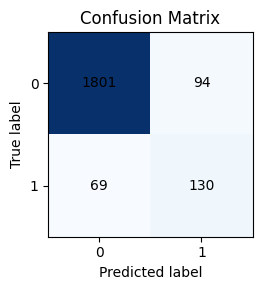

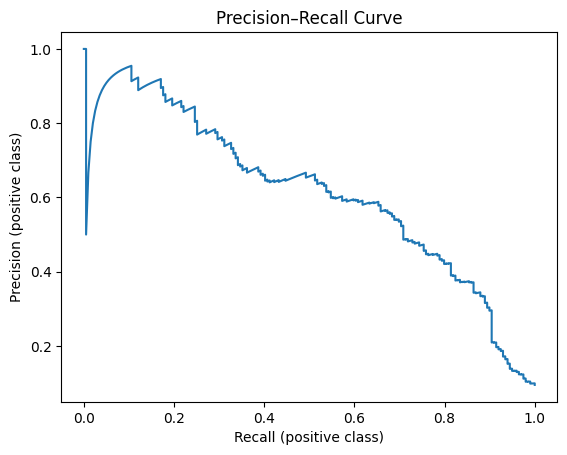

{'ap': 0.613854136605239,
 'cm': [[1801, 94], [69, 130]],
 'thr': 0.32999999999999996}

In [46]:
print('--- Local Evaluation 2: Custom Metrics ---')
local_custom_metrics(y_dev, dev_probs, thr)

## 7 Write dev.txt and test.txt

In [48]:
def write_predictions(path, labels):
    with open(path, 'w') as f:
        for y in labels:
            f.write(f'{int(y)}\n')
    print(f'Wrote {len(labels)} lines to {path}')

In [49]:
df_test_final = pd.read_csv(TEST_PATH, sep='\t', header=None, names=col_names_test)
df_test_processed = build_model_input(df_test_final, use_metadata=USE_METADATA)

test_final_ds = PCLDataset(df_test_processed, 'model_input', None, tokenizer, MAX_LEN)

final_test_output = trainer.predict(test_final_ds)
final_test_probs = probs_from_logits(final_test_output.predictions)
final_test_preds = (final_test_probs >= best_threshold).astype(int)

In [50]:
write_predictions(OUT_DIR / 'test.txt', final_test_preds)
write_predictions(OUT_DIR / 'dev.txt', dev_preds)

Wrote 3832 lines to /vol/bitbucket/ak5323/nlp_cw_2026_ak5323/output/test.txt
Wrote 2094 lines to /vol/bitbucket/ak5323/nlp_cw_2026_ak5323/output/dev.txt
